# FlashAttention live CUDA demonstration

### Fresh inputs → CUDA attention → Numerical verification → Measured performance

**Live system: RTX 4070 Ti** · Historical full run: **RTX 3070 Ti Laptop GPU**

The detected GPU and execution time accompany each new measurement. Latencies and speedups may differ from the full-run slides because the GPU and demo configurations differ. Saved notebook outputs record their displayed execution time.

In [ ]:
from pathlib import Path
import json,sys,html,os,hashlib,subprocess,statistics
from urllib.parse import quote
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,HTML,Markdown

BASE=Path.cwd().resolve()
REPO=Path(os.environ['FLASH_ATTENTION_REPO']).resolve() if os.environ.get('FLASH_ATTENTION_REPO') else next((p for p in [BASE/"Flash-Attention-CUDA",BASE]
           if (p/"part_a/common/attention_types.hpp").is_file()
           and (p/"part_c/src/flash_attention_2_tensor_core.cu").is_file()),None)
if REPO is None:raise FileNotFoundError("Open JupyterLab in the parent of the Flash-Attention-CUDA checkout, or its root.")
WORK=BASE/"flash_attention_live_demo"
SOURCE=WORK/"source"
SOURCE.mkdir(parents=True,exist_ok=True)
EMBEDDED={'demo_runner.cu': '#include "attention_types.hpp"\n#include "input_generation.hpp"\n#include "flash_attention/dense_flash_attention.h"\n#include "flash_attention/flash_attention_2_tensor_core.h"\n#include <cuda_runtime.h>\n#include <cuda_fp16.h>\n#include <algorithm>\n#include <cmath>\n#include <fstream>\n#include <iomanip>\n#include <iostream>\n#include <stdexcept>\n#include <string>\n#include <vector>\n\nvoid check(cudaError_t e){if(e!=cudaSuccess)throw std::runtime_error(cudaGetErrorString(e));}\nstruct Allocations {\n    std::vector<void*> pointers;size_t bytes=0;\n    template<class T>T* get(size_t n){T* p=nullptr;check(cudaMalloc((void**)&p,n*sizeof(T)));pointers.push_back(p);bytes+=n*sizeof(T);return p;}\n    ~Allocations(){for(void* p:pointers)cudaFree(p);}\n};\nstruct Record {\n    std::string name;size_t allocated=0,checked=0,failures=0,nonfinite=0;\n    double maximum=0;std::vector<float> times,output;\n};\ntemplate<class T>void upload(T* p,const std::vector<T>& v){check(cudaMemcpy(p,v.data(),v.size()*sizeof(T),cudaMemcpyHostToDevice));}\ntemplate<class F>void execute(Record& r,F forward,float* output,size_t count,int repeats,const std::vector<double>& expected,double atol,double rtol){\n    check(cudaMemset(output,0xff,count*sizeof(float)));\n    forward();check(cudaGetLastError());check(cudaDeviceSynchronize());\n    r.output.resize(count);check(cudaMemcpy(r.output.data(),output,count*sizeof(float),cudaMemcpyDeviceToHost));\n    for(size_t i=0;i<count;++i){\n        if(!std::isfinite(r.output[i])){++r.nonfinite;continue;}\n        if(std::isnan(expected[i]))continue;\n        ++r.checked;double error=std::abs(double(r.output[i])-expected[i]);\n        r.maximum=std::max(r.maximum,error);\n        if(error>atol+rtol*std::abs(expected[i]))++r.failures;\n    }\n    if(r.nonfinite||r.failures||!r.checked)return;\n    for(int i=0;i<5;++i)forward();check(cudaDeviceSynchronize());\n    cudaEvent_t begin,end;check(cudaEventCreate(&begin));check(cudaEventCreate(&end));\n    for(int i=0;i<repeats;++i){check(cudaEventRecord(begin));forward();check(cudaEventRecord(end));check(cudaEventSynchronize(end));float ms;check(cudaEventElapsedTime(&ms,begin,end));r.times.push_back(ms);}\n    check(cudaEventDestroy(begin));check(cudaEventDestroy(end));\n}\nvoid array(std::ostream& o,const std::vector<float>& v,size_t begin,size_t count){\n    o<<\'[\';for(size_t i=0;i<count;++i){if(i)o<<\',\';float x=v.at(begin+i);if(std::isfinite(x))o<<x;else o<<"null";}o<<\']\';\n}\nint main(int argc,char** argv){try{\n    if((argc==2&&std::string(argv[1])=="--device")||(argc==3&&std::string(argv[1])=="--device-json")){\n        cudaDeviceProp p{};check(cudaGetDeviceProperties(&p,0));int driver=0,runtime=0;check(cudaDriverGetVersion(&driver));check(cudaRuntimeGetVersion(&runtime));\n        std::ofstream file;\n        if(argc==3){file.open(argv[2]);if(!file)throw std::runtime_error("cannot write device JSON file");}\n        std::ostream& out=argc==3?static_cast<std::ostream&>(file):std::cout;\n        out<<"{\\"name\\":\\""<<p.name<<"\\",\\"sm\\":"<<p.major*10+p.minor<<",\\"total_bytes\\":"<<p.totalGlobalMem<<",\\"driver\\":"<<driver<<",\\"runtime\\":"<<runtime<<"}\\n";out.flush();if(!out)throw std::runtime_error("device JSON write failed");return 0;\n    }\n    if(argc!=9)throw std::invalid_argument("usage: demo_runner ptx|dense B H N d SEED REPEATS OUTPUT.json");\n    std::string mode=argv[1];if(mode!="ptx"&&mode!="dense")throw std::invalid_argument("unknown mode");\n    attention::Shape s{size_t(std::stoi(argv[2])),size_t(std::stoi(argv[3])),size_t(std::stoi(argv[4])),size_t(std::stoi(argv[5]))};\n    if(s.B<1||s.B>4||s.H<1||s.H>8||s.N<16||s.N>2048||s.d!=64)throw std::invalid_argument("demo limits: B 1..4, H 1..8, N 16..2048, d=64");\n    auto seed=std::stoull(argv[6]);int repeats=std::stoi(argv[7]);if(repeats<5||repeats>100)throw std::invalid_argument("repeats 5..100");\n    const bool tc=mode=="ptx",causal=tc,sampled=s.N>256;const size_t count=attention::input_elements(s),scores=s.B*s.H*s.N*s.N;\n    auto input=attention::synthetic_input(s,seed);auto q=input.q,k=input.k,v=input.v;\n    std::vector<half> hq,hk,hv;\n    if(tc){hq.resize(count);hk.resize(count);hv.resize(count);for(size_t i=0;i<count;++i){hq[i]=__float2half_rn(q[i]);hk[i]=__float2half_rn(k[i]);hv[i]=__float2half_rn(v[i]);q[i]=__half2float(hq[i]);k[i]=__half2float(hk[i]);v[i]=__half2float(hv[i]);}}\n    auto expected=attention::reference_output(s,q,k,v,causal,sampled);\n    const double atol=tc?0.002:0.0001,rtol=tc?0.02:0.0001;\n    std::vector<Record> records;\n    for(int implementation=0;implementation<2;++implementation){\n        Allocations mem;Record r;r.name=implementation==0?(tc?"A materialised PTX":"A optimized FP32"):(tc?"C fused PTX FA2":"B fused FP32");\n        float* out=mem.get<float>(count);\n        if(tc){\n            half* dq=mem.get<half>(count),*dk=mem.get<half>(count),*dv=mem.get<half>(count);upload(dq,hq);upload(dk,hk);upload(dv,hv);\n            if(implementation==0){\n                float* ds=mem.get<float>(scores);half* dp=mem.get<half>(scores);\n                auto f=[&](){attention::detail::launch_qk_tensorcore(dq,dk,ds,s,true,true);attention::detail::launch_softmax_mixed(ds,dp,s,true,256);attention::detail::launch_pv_tensorcore(dp,dv,out,s,true);};\n                execute(r,f,out,count,repeats,expected,atol,rtol);\n            }else{\n                part_c::Shape cs{int(s.B),int(s.H),int(s.N),int(s.d)};part_c::DevicePointers buffers{nullptr,nullptr,nullptr,out,dq,dk,dv};\n                auto f=[&](){part_c::launch_flash_attention_2_tensor_core_configured(part_c::TensorCoreVariant::PtxMma,cs,buffers,0);};\n                execute(r,f,out,count,repeats,expected,atol,rtol);\n            }\n        }else{\n            float* dq=mem.get<float>(count),*dk=mem.get<float>(count),*dv=mem.get<float>(count);upload(dq,q);upload(dk,k);upload(dv,v);\n            if(implementation==0){\n                float* ds=mem.get<float>(scores),*dp=mem.get<float>(scores);\n                auto f=[&](){attention::detail::launch_qk_tiled(dq,dk,ds,s,false,16);attention::detail::launch_softmax_parallel(ds,dp,s,false,256);attention::detail::launch_pv_tiled(dp,dv,out,s,16);};\n                execute(r,f,out,count,repeats,expected,atol,rtol);\n            }else{\n                dense_attention::Config cfg;cfg.variant="vector";cfg.warps=4;cfg.key_tile=32;\n                auto f=[&](){dense_attention::forward(dq,dk,dv,out,s,cfg);};\n                execute(r,f,out,count,repeats,expected,atol,rtol);\n            }\n        }\n        r.allocated=mem.bytes;records.push_back(std::move(r));\n    }\n    cudaDeviceProp gpu{};check(cudaGetDeviceProperties(&gpu,0));\n    size_t preview=(s.N/2)*s.d;\n    std::ofstream o(argv[8]);if(!o)throw std::runtime_error("cannot create output JSON");o<<std::setprecision(10);\n    o<<"{\\"gpu\\":\\""<<gpu.name<<"\\",\\"sm\\":"<<gpu.major*10+gpu.minor<<",\\"mode\\":\\""<<(causal?"causal":"dense")<<"\\",\\"precision\\":\\""<<(tc?"FP16 inputs / FP32 accumulation and output":"FP32")<<"\\",\\"B\\":"<<s.B<<",\\"H\\":"<<s.H<<",\\"N\\":"<<s.N<<",\\"d\\":"<<s.d<<",\\"seed\\":"<<seed<<",\\"input_digest\\":\\""<<attention::input_fingerprint(q,k,v)<<"\\",\\"reference_scope\\":\\""<<(sampled?"sampled query rows 0,N/2,N-1 in every head":"full output")<<"\\",\\"atol\\":"<<atol<<",\\"rtol\\":"<<rtol<<",\\"warmup\\":5,\\"repeats\\":"<<repeats<<",\\"preview_query\\":"<<s.N/2<<",\\"q_preview\\":";array(o,q,preview,8);\n    o<<",\\"reference_preview\\":[";for(size_t i=0;i<8;++i){if(i)o<<\',\';o<<expected[preview+i];}o<<"],\\"configuration\\":\\"A tile16 softmax256 / A PTX softmax256; B vector warps4 key32; C PTX config0; fixed demo choices, no tuning\\",\\"records\\":[";\n    bool passed=true;\n    for(size_t i=0;i<records.size();++i){if(i)o<<\',\';const auto& r=records[i];bool ok=!r.failures&&!r.nonfinite&&r.checked;passed&=ok;\n        o<<"{\\"implementation\\":\\""<<r.name<<"\\",\\"passed\\":"<<(ok?"true":"false")<<",\\"checked_elements\\":"<<r.checked<<",\\"failures\\":"<<r.failures<<",\\"nonfinite\\":"<<r.nonfinite<<",\\"max_absolute_error\\":"<<r.maximum<<",\\"allocated_bytes\\":"<<r.allocated<<",\\"output_preview\\":";array(o,r.output,preview,8);o<<",\\"samples_ms\\":";array(o,r.times,0,r.times.size());o<<\'}\';}\n    o<<"],\\"passed\\":"<<(passed?"true":"false")<<"}\\n";o.close();\n    std::cout<<(passed?"PASS":"FAIL")<<" "<<mode<<" N="<<s.N<<" seed="<<seed<<\'\\n\';return passed?0:2;\n}catch(const std::exception& e){std::cerr<<e.what()<<\'\\n\';return 1;}}\n', 'CMakeLists.txt': 'cmake_minimum_required(VERSION 3.20)\nproject(attention_live_demo LANGUAGES CXX CUDA)\nfind_package(CUDAToolkit REQUIRED)\nif(NOT DEFINED ATTENTION_REPO)\n  message(FATAL_ERROR "ATTENTION_REPO is required")\nendif()\nadd_executable(demo_runner demo_runner.cu\n  ${ATTENTION_REPO}/part_a/cpu_reference/sampled_reference.cpp\n  ${ATTENTION_REPO}/part_a/gpu_baseline/matmul_tiled.cu\n  ${ATTENTION_REPO}/part_a/gpu_baseline/softmax_parallel.cu\n  ${ATTENTION_REPO}/part_a/gpu_baseline/matmul_tensorcore.cu\n  ${ATTENTION_REPO}/part_b/src/dense_flash_attention.cu\n  ${ATTENTION_REPO}/part_c/src/flash_attention_2_tensor_core.cu)\ntarget_include_directories(demo_runner PRIVATE ${ATTENTION_REPO}/part_a/common ${ATTENTION_REPO}/part_b/include ${ATTENTION_REPO}/part_c/include)\ntarget_compile_definitions(demo_runner PRIVATE PART_A_ENABLE_CUDA NOMINMAX)\ntarget_link_libraries(demo_runner PRIVATE CUDA::cudart)\nset_target_properties(demo_runner PROPERTIES CXX_STANDARD 17 CUDA_STANDARD 17 CXX_STANDARD_REQUIRED ON CUDA_STANDARD_REQUIRED ON)\n', 'live_demo.py': 'from pathlib import Path\nimport os,sys,json,csv,subprocess,shutil,hashlib,time,uuid,statistics\nfrom datetime import datetime,timezone\n\nREPO_FILES=[\n \'part_a/common/attention_types.hpp\',\'part_a/common/input_generation.hpp\',\n \'part_a/cpu_reference/sampled_reference.cpp\',\n \'part_a/gpu_baseline/matmul_tiled.cu\',\'part_a/gpu_baseline/softmax_parallel.cu\',\'part_a/gpu_baseline/matmul_tensorcore.cu\',\n \'part_b/include/flash_attention/dense_flash_attention.h\',\'part_b/src/dense_flash_attention.cu\',\n \'part_c/include/flash_attention/types.h\',\'part_c/include/flash_attention/flash_attention_2_tensor_core.h\',\n \'part_c/src/flash_attention_2_tensor_core.cu\']\n\ndef sha(path):return hashlib.sha256(Path(path).read_bytes()).hexdigest()\ndef read_json(path,label):\n    path=Path(path)\n    try:\n        raw=path.read_text(encoding=\'utf-8-sig\')\n        if not raw.strip():raise ValueError(\'file is empty\')\n        value=json.loads(raw)\n        if not isinstance(value,dict):raise ValueError(\'expected a JSON object\')\n        return value\n    except (OSError,ValueError) as e:\n        raise RuntimeError(f\'{label}: cannot read valid JSON from {path}: {e}\') from e\n\ndef write_json(path,value):\n    path=Path(path);temporary=path.with_name(path.name+\'.\'+uuid.uuid4().hex+\'.tmp\')\n    temporary.write_text(json.dumps(value,indent=2),encoding=\'utf-8\')\n    temporary.replace(path)\ndef command(args,env=None,timeout=60):\n    r=subprocess.run([str(a) for a in args],env=env,capture_output=True,text=True,timeout=timeout)\n    if r.returncode:raise RuntimeError(\'Command failed: \'+str(args[0])+\'\\n\'+r.stdout[-2000:]+r.stderr[-2000:])\n    return r.stdout.strip()\n\ndef compiler_environment():\n    env=os.environ.copy()\n    if os.name!=\'nt\' or shutil.which(\'cl\',path=env.get(\'PATH\')):return env\n    vswhere=Path(env.get(\'ProgramFiles(x86)\',r\'C:\\Program Files (x86)\'))/\'Microsoft Visual Studio/Installer/vswhere.exe\'\n    if not vswhere.is_file():raise RuntimeError(\'Install Visual Studio C++ Build Tools, or start JupyterLab from an x64 Native Tools prompt.\')\n    # CUDA 12.x uses the supported VS2022 host rather than a newer VS18 preview.\n    installation=command([vswhere,\'-latest\',\'-products\',\'*\',\'-version\',\'[17.0,18.0)\',\'-requires\',\'Microsoft.VisualStudio.Component.VC.Tools.x86.x64\',\'-property\',\'installationPath\'])\n    if not installation:raise RuntimeError(\'Visual Studio 2022 C++ Build Tools are required for this CUDA 12.x notebook build.\')\n    script=Path(installation)/\'VC/Auxiliary/Build/vcvars64.bat\'\n    if not script.is_file():raise RuntimeError(\'Visual Studio x64 C++ toolchain not found.\')\n    r=subprocess.run(\'call "\'+str(script)+\'" >nul && set\',shell=True,capture_output=True,text=True)\n    if r.returncode:raise RuntimeError(\'Cannot initialize Visual Studio: \'+r.stderr)\n    for line in r.stdout.splitlines():\n        if \'=\' in line:\n            k,v=line.split(\'=\',1)\n            if k:env[k]=v\n    return env\n\ndef prepare(repo,work,source):\n    repo,work,source=map(Path,(repo,work,source));env=compiler_environment()\n    for tool in [\'cmake\',\'nvcc\',\'nvidia-smi\']:\n        if not shutil.which(tool,path=env.get(\'PATH\')):raise RuntimeError(tool+\' is required. See the presenter preparation notes.\')\n    report=command([\'nvidia-smi\',\'--id=0\',\'--query-gpu=name,uuid,compute_cap\',\'--format=csv,noheader\'],env)\n    name,gpu_uuid,cap=[v.strip() for v in report.splitlines()[0].split(\',\')]\n    arch=cap.replace(\'.\',\'\')\n    if int(arch)<80:raise RuntimeError(\'The PTX demonstration requires SM80 or newer.\')\n    hashes={n:sha(repo/n) for n in REPO_FILES}\n    driver_hashes={n:sha(source/n) for n in [\'demo_runner.cu\',\'CMakeLists.txt\',\'live_demo.py\']}\n    nvcc=command([\'nvcc\',\'--version\'],env)\n    identity={\'repo_sources\':hashes,\'demo_sources\':driver_hashes,\'arch\':arch,\'nvcc\':nvcc}\n    key=hashlib.sha256(json.dumps(identity,sort_keys=True).encode()).hexdigest()[:16]\n    build=work/\'build\'/key;build.mkdir(parents=True,exist_ok=True)\n    executable=build/(\'demo_runner.exe\' if os.name==\'nt\' else \'demo_runner\')\n    manifest_path=build/\'build_manifest.json\'\n    cached=False\n    if executable.is_file() and manifest_path.is_file():\n        try:\n            old=read_json(manifest_path,\'Cached build manifest\')\n            cached=old.get(\'identity\')==identity and old.get(\'executable_sha256\')==sha(executable)\n        except RuntimeError:\n            print(\'Cached build manifest is incomplete; rebuilding and replacing it atomically.\',flush=True)\n    if not cached:\n        generator=\'Ninja\' if shutil.which(\'ninja\',path=env.get(\'PATH\')) else (\'NMake Makefiles\' if os.name==\'nt\' else \'Unix Makefiles\')\n        args=[\'cmake\',\'-S\',str(source),\'-B\',str(build),\'-G\',generator,\n              \'-DATTENTION_REPO=\'+repo.as_posix(),\'-DCMAKE_BUILD_TYPE=Release\',\n              \'-DCMAKE_CUDA_ARCHITECTURES=\'+arch,\'-DCMAKE_POLICY_DEFAULT_CMP0141=NEW\',\n              \'-DCMAKE_MSVC_DEBUG_INFORMATION_FORMAT=Embedded\']\n        if os.name==\'nt\':args.append(\'-DCMAKE_CUDA_FLAGS=-allow-unsupported-compiler\')\n        log=build/\'build.log\'\n        print(\'Preparing repository CUDA kernels for SM\'+arch+\'; first build may take several minutes.\',flush=True)\n        with log.open(\'w\',encoding=\'utf-8\') as f:\n            for cmd in [args,[\'cmake\',\'--build\',str(build),\'--parallel\',\'2\']]:\n                f.write(json.dumps(cmd)+\'\\n\');f.flush()\n                r=subprocess.run(cmd,env=env,stdout=f,stderr=subprocess.STDOUT,timeout=900)\n                if r.returncode:raise RuntimeError(\'CUDA build failed. Read \'+str(log)+\'\\n\'+log.read_text(encoding=\'utf-8\',errors=\'replace\')[-5000:])\n        if not executable.is_file():raise RuntimeError(\'Build did not produce demo_runner.\')\n        write_json(manifest_path,{\'identity\':identity,\'executable_sha256\':sha(executable),\'built_utc\':datetime.now(timezone.utc).isoformat()})\n    # Use a real output file instead of assuming stdout contains only JSON.\n    device_file=build/(\'device_\'+uuid.uuid4().hex+\'.json\')\n    proc=subprocess.run([str(executable),\'--device-json\',str(device_file)],env=env,capture_output=True,text=True,timeout=60)\n    diagnostic=f\'GPU query executable: {executable}\\nExit code: {proc.returncode}\\nstdout: {proc.stdout[-2000:]!r}\\nstderr: {proc.stderr[-2000:]!r}\'\n    if proc.returncode:raise RuntimeError(\'CUDA device query failed.\\n\'+diagnostic)\n    try:\n        device=read_json(device_file,\'CUDA device query\')\n        for field in [\'name\',\'sm\',\'total_bytes\',\'driver\',\'runtime\']:\n            if field not in device:raise RuntimeError(\'CUDA device JSON is missing \'+field)\n    except RuntimeError as e:raise RuntimeError(str(e)+\'\\n\'+diagnostic) from e\n    device[\'uuid\']=gpu_uuid;device[\'reported_by_nvidia_smi\']=name\n    if str(device[\'sm\'])!=arch:raise RuntimeError(\'CUDA device architecture differs from the selected nvidia-smi GPU.\')\n    git={}\n    for label,args in [(\'commit\',[\'rev-parse\',\'HEAD\']),(\'status\',[\'status\',\'--porcelain\'])]:\n        try:git[label]=command([\'git\',\'-C\',repo,*args],timeout=10)\n        except Exception:git[label]=\'unavailable; repository file SHA-256 hashes retained\'\n    session=work/\'runs\'/(datetime.now(timezone.utc).strftime(\'%Y%m%dT%H%M%SZ\')+\'_\'+uuid.uuid4().hex[:8]);session.mkdir(parents=True)\n    provenance={\'device\':device,\'build_manifest\':read_json(manifest_path,\'Build provenance\'),\'git\':git,\n                \'repository\':str(repo),\'session_utc\':datetime.now(timezone.utc).isoformat(),\n                \'historical_gpu\':\'RTX 3070 Ti Laptop GPU\',\'live_results_are_new\':True}\n    write_json(session/\'provenance.json\',provenance)\n    return {\'repo\':repo,\'work\':work,\'exe\':executable,\'env\':env,\'device\':device,\'session\':session,\'cached_build\':cached}\n\ndef run_case(context,n=512,seed=20261113,mode=\'ptx\',b=4,h=8,repeats=20):\n    if mode not in (\'ptx\',\'dense\'):raise ValueError(\'Choose ptx or dense.\')\n    if not (16<=int(n)<=2048):raise ValueError(\'N must be between 16 and 2048 for this short demo.\')\n    output=context[\'session\']/(mode+\'_N\'+str(n)+\'_\'+uuid.uuid4().hex[:8]+\'.json\')\n    args=[context[\'exe\'],mode,b,h,n,64,seed,repeats,output]\n    started=time.perf_counter()\n    proc=subprocess.run([str(a) for a in args],env=context[\'env\'],capture_output=True,text=True,timeout=180)\n    if not output.is_file():raise RuntimeError(proc.stdout+\'\\n\'+proc.stderr)\n    try:data=read_json(output,\'Live CUDA result\')\n    except RuntimeError as e:raise RuntimeError(str(e)+f\'\\nExit code: {proc.returncode}\\nstdout: {proc.stdout[-2000:]!r}\\nstderr: {proc.stderr[-2000:]!r}\') from e\n    data[\'wall_seconds\']=time.perf_counter()-started\n    data[\'created_utc\']=datetime.now(timezone.utc).isoformat();data[\'result_path\']=str(output)\n    data[\'gpu_uuid\']=context[\'device\'][\'uuid\'];data[\'build_manifest\']=\'provenance.json\'\n    data[\'command\']=[str(a) for a in args]\n    write_json(output,data)\n    if proc.returncode or not data[\'passed\']:raise RuntimeError(\'Fresh GPU validation failed; raw evidence retained at \'+str(output)+\'\\n\'+proc.stderr)\n    for r in data[\'records\']:\n        if len(r[\'samples_ms\'])!=repeats or not all(x>0 for x in r[\'samples_ms\']):raise RuntimeError(\'Incomplete/invalid CUDA-event samples.\')\n    return data\n\ndef median(record):return statistics.median(record[\'samples_ms\'])\n'}
for name,contents in EMBEDDED.items():
    p=SOURCE/name
    if not p.is_file() or p.read_text(encoding="utf-8")!=contents:p.write_text(contents,encoding="utf-8")
import importlib.util
spec=importlib.util.spec_from_file_location("attention_live_helpers",SOURCE/"live_demo.py")
live=importlib.util.module_from_spec(spec);spec.loader.exec_module(live)

def table(rows):
    keys=list(rows[0]);out="<table><tr>"+"".join("<th>"+html.escape(k)+"</th>" for k in keys)+"</tr>"
    for row in rows:out+="<tr>"+"".join("<td>"+html.escape(str(row[k]))+"</td>" for k in keys)+"</tr>"
    display(HTML(out+"</table>"))

def sources(*names):
    items=[]
    for n in names:
        p=REPO/n;url=quote(Path(os.path.relpath(p,BASE)).as_posix(),safe="/")
        items.append('<a href="'+url+'">'+html.escape(n)+'</a> ['+live.sha(p)[:12]+']')
    display(HTML('<p style="font-size:11px;color:#555">Repository sources: '+' · '.join(items)+'</p>'))

def result_link(r):
    url=quote(Path(os.path.relpath(r["result_path"],BASE)).as_posix(),safe="/")
    display(HTML('<p style="font-size:11px;color:#555">Execution '+html.escape(r['created_utc'])+' · Input fingerprint '+r['input_digest']+' · <a href="'+url+'">Raw live result and 20 timing samples per implementation</a></p>'))

def show_case(r,preview=False):
    display(Markdown('**'+r['gpu']+' · '+r['mode']+' · '+r['precision']+'**'))
    display(Markdown(f"B={r['B']}, H={r['H']}, N={r['N']}, d={r['d']}, seed={r['seed']} · FP64 reference: **{r['reference_scope']}**"))
    rows=[]
    for x in r['records']:
        q1,q3=np.quantile(x['samples_ms'],[.25,.75])
        rows.append({'Implementation':x['implementation'],'Check':'PASS' if x['passed'] else 'FAIL',
                     'Max abs. error':f"{x['max_absolute_error']:.3g}",'Checked values':x['checked_elements'],
                     'Median ms':f"{live.median(x):.4f}",'IQR ms':f"{q1:.4f}–{q3:.4f}",
                     'Allocated MiB':f"{x['allocated_bytes']/2**20:.2f}"})
    table(rows)
    a,b=r['records']
    display(Markdown(f"**A / fused median latency: {live.median(a)/live.median(b):.2f}×** · Above 1 favours the fused implementation. "+
                     f"**Allocated tensor capacity: {a['allocated_bytes']/b['allocated_bytes']:.2f}× lower** for the fused path."))
    if preview:
        rows=[{'Output':f'CPU FP64, query {r["preview_query"]}', 'First 8 features':', '.join(f'{v:.5f}' for v in r['reference_preview'])}]
        rows += [{'Output':x['implementation'],'First 8 features':', '.join(f'{v:.5f}' for v in x['output_preview'])} for x in r['records']]
        table(rows)
        display(Markdown(f"Acceptance: |error| ≤ {r['atol']} + {r['rtol']} × |reference|. All GPU output values are scanned for nonfinite values."))
    result_link(r)
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})


## Live device and repository build

In [ ]:
CTX=live.prepare(REPO,WORK,SOURCE)
table([{'Live GPU':CTX['device']['name'],'Architecture':'SM'+str(CTX['device']['sm']),
        'VRAM GiB':f"{CTX['device']['total_bytes']/2**30:.1f}",
        'Historical full-run GPU':'RTX 3070 Ti Laptop GPU'}])
display(Markdown('**Fresh CUDA execution is enabled.** Fixed demo configurations; 5 warm-ups and 20 unprofiled CUDA-event samples per implementation.'))
display(Markdown('Raw measurements and source hashes are saved in `'+str(CTX['session'].relative_to(BASE))+'`.'))
sources('part_a/common/input_generation.hpp','part_a/cpu_reference/sampled_reference.cpp')

## Fresh workload

In [3]:
SEED = 20261113
N = 512
N_LARGER = 1024

## 1 · Compute and verify attention

Small causal example · FP16 inputs · FP32 accumulation and output · full CPU FP64 reference

In [4]:
proof=live.run_case(CTX,n=128,seed=SEED,mode='ptx',b=1,h=1)
show_case(proof,preview=True)
sources('part_a/gpu_baseline/matmul_tensorcore.cu','part_c/src/flash_attention_2_tensor_core.cu')

**NVIDIA GeForce RTX 4070 Ti · causal · FP16 inputs / FP32 accumulation and output**

B=1, H=1, N=128, d=64, seed=20261113 · FP64 reference: **full output**

Implementation,Check,Max abs. error,Checked values,Median ms,IQR ms,Allocated MiB
A materialised PTX,PASS,0.000138,8192,0.0215,0.0179–0.0318,0.17
C fused PTX FA2,PASS,0.000113,8192,0.0338,0.0328–0.0369,0.08


**A / fused median latency: 0.63×** · Above 1 favours the fused implementation. **Allocated tensor capacity: 2.20× lower** for the fused path.

Output,First 8 features
"CPU FP64, query 64","-0.00950, -0.01318, -0.02464, -0.08254, -0.02094, -0.03828, -0.04800, -0.01669"
A materialised PTX,"-0.00950, -0.01321, -0.02463, -0.08254, -0.02095, -0.03828, -0.04800, -0.01669"
C fused PTX FA2,"-0.00950, -0.01319, -0.02464, -0.08254, -0.02094, -0.03833, -0.04801, -0.01669"


Acceptance: |error| ≤ 0.002 + 0.02 × |reference|. All GPU output values are scanned for nonfinite values.

Execution 2026-11-12T23:53:12.288580+00:00 · Input fingerprint 50569f02469e80d8 · Raw live result and 20 timing samples per implementation

Repository sources: part_a/gpu_baseline/matmul_tensorcore.cu [140d39261ad4] · part_c/src/flash_attention_2_tensor_core.cu [32f0093593b6]

## 2 · Measure matched CUDA implementations

Causal materialised A-PTX versus fused C-PTX FA2 · same effective Q/K/V inputs in each comparison

In [5]:
first=live.run_case(CTX,n=N,seed=SEED,mode='ptx')
show_case(first)
sources('part_a/gpu_baseline/matmul_tensorcore.cu','part_a/gpu_baseline/softmax_parallel.cu','part_c/src/flash_attention_2_tensor_core.cu')

**NVIDIA GeForce RTX 4070 Ti · causal · FP16 inputs / FP32 accumulation and output**

B=4, H=8, N=512, d=64, seed=20261113 · FP64 reference: **sampled query rows 0,N/2,N-1 in every head**

Implementation,Check,Max abs. error,Checked values,Median ms,IQR ms,Allocated MiB
A materialised PTX,PASS,2.82e-05,6144,0.3786,0.3759–0.4093,58.00
C fused PTX FA2,PASS,3.03e-05,6144,0.1565,0.1546–0.1594,10.00


**A / fused median latency: 2.42×** · Above 1 favours the fused implementation. **Allocated tensor capacity: 5.80× lower** for the fused path.

Execution 2026-11-12T23:53:12.573604+00:00 · Input fingerprint c3319b16f85774e1 · Raw live result and 20 timing samples per implementation

Repository sources: part_a/gpu_baseline/matmul_tensorcore.cu [140d39261ad4] · part_a/gpu_baseline/softmax_parallel.cu [a7d09faf5b95] · part_c/src/flash_attention_2_tensor_core.cu [32f0093593b6]

## 3 · Increase sequence length

New GPU executions · forward latency and allocated tensor capacity

**NVIDIA GeForce RTX 4070 Ti · causal · FP16 inputs / FP32 accumulation and output**

B=4, H=8, N=1024, d=64, seed=20261113 · FP64 reference: **sampled query rows 0,N/2,N-1 in every head**

Implementation,Check,Max abs. error,Checked values,Median ms,IQR ms,Allocated MiB
A materialised PTX,PASS,2.24e-05,6144,1.5185,1.5132–1.5347,212.00
C fused PTX FA2,PASS,1.87e-05,6144,0.4588,0.4536–0.5146,20.00


**A / fused median latency: 3.31×** · Above 1 favours the fused implementation. **Allocated tensor capacity: 10.60× lower** for the fused path.

Execution 2026-11-12T23:53:12.970312+00:00 · Input fingerprint c52e6eddd71a7aa0 · Raw live result and 20 timing samples per implementation

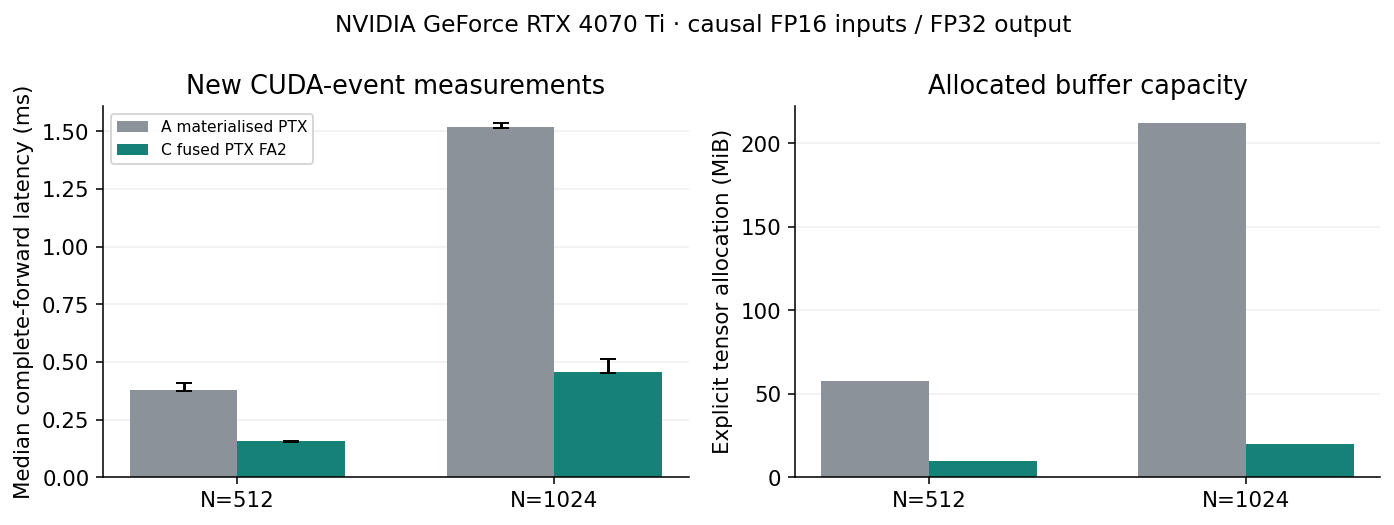

Timings exclude compilation, allocation, input transfers and CPU validation. Memory is the sum of requested CUDA tensor buffers, not DRAM traffic or total process peak.

In [6]:
if N_LARGER<=N:raise ValueError('N_LARGER must exceed N.')
larger=live.run_case(CTX,n=N_LARGER,seed=SEED,mode='ptx')
show_case(larger)
fig,axes=plt.subplots(1,2,figsize=(10,3.8))
xs=np.arange(2);width=.34
for j,color in [(0,'#8b9299'),(1,'#168277')]:
    rows=[first['records'][j],larger['records'][j]]
    vals=np.array([live.median(x) for x in rows]);q=np.array([np.quantile(x['samples_ms'],[.25,.75]) for x in rows])
    axes[0].bar(xs+(j-.5)*width,vals,width,label=rows[0]['implementation'],color=color,
                yerr=np.vstack([vals-q[:,0],q[:,1]-vals]),capsize=4)
    axes[1].bar(xs+(j-.5)*width,[x['allocated_bytes']/2**20 for x in rows],width,label=rows[0]['implementation'],color=color)
for ax in axes:
    ax.set_xticks(xs,[f'N={N}',f'N={N_LARGER}']);ax.grid(axis='y',alpha=.2);ax.set_axisbelow(True)
axes[0].set(ylabel='Median complete-forward latency (ms)',title='New CUDA-event measurements')
axes[1].set(ylabel='Explicit tensor allocation (MiB)',title='Allocated buffer capacity')
axes[0].legend(fontsize=8)
fig.suptitle(CTX['device']['name']+' · causal FP16 inputs / FP32 output',fontsize=12)
fig.tight_layout();plt.show()
display(Markdown('Timings exclude compilation, allocation, input transfers and CPU validation. Memory is the sum of requested CUDA tensor buffers, not DRAM traffic or total process peak.'))

## 4 · Part B live trade-off

Dense FP32 · materialised optimized A versus fused B · no Tensor Core B

In [7]:
dense=live.run_case(CTX,n=N_LARGER,seed=SEED,mode='dense')
show_case(dense)
a,b=dense['records']
relative=live.median(b)/live.median(a)
display(Markdown(f"**Observed now:** B uses {a['allocated_bytes']/b['allocated_bytes']:.2f}× less allocated tensor capacity; "+
                 (f"takes {relative:.2f}× as long as A." if relative>=1 else f"is {1/relative:.2f}× faster than A.")))
sources('part_a/gpu_baseline/matmul_tiled.cu','part_a/gpu_baseline/softmax_parallel.cu','part_b/src/dense_flash_attention.cu')

**NVIDIA GeForce RTX 4070 Ti · dense · FP32**

B=4, H=8, N=1024, d=64, seed=20261113 · FP64 reference: **sampled query rows 0,N/2,N-1 in every head**

Implementation,Check,Max abs. error,Checked values,Median ms,IQR ms,Allocated MiB
A optimized FP32,PASS,6.4e-08,6144,3.2592,3.2457–3.2742,288.00
B fused FP32,PASS,2.15e-08,6144,7.8864,7.6661–8.3305,32.00


**A / fused median latency: 0.41×** · Above 1 favours the fused implementation. **Allocated tensor capacity: 9.00× lower** for the fused path.

Execution 2026-11-12T23:53:14.667804+00:00 · Input fingerprint 97667e1c15ce2db9 · Raw live result and 20 timing samples per implementation

**Observed now:** B uses 9.00× less allocated tensor capacity; takes 2.42× as long as A.

Repository sources: part_a/gpu_baseline/matmul_tiled.cu [222689ba6751] · part_a/gpu_baseline/softmax_parallel.cu [a7d09faf5b95] · part_b/src/dense_flash_attention.cu [3af6d127705f]

## What this demonstrates

- Repository CUDA kernels compute attention on newly generated inputs.
- Numerical checks accompany each new timing result.
- Sequence length changes both storage and execution cost.
- Memory savings and latency gains are measured separately.

**RTX 4070 Ti live measurements and RTX 3070 Ti Laptop full-run measurements are separate experiments.** This short demonstration adds new executions; it does not replace the full correctness grid, sanitizers or profiler captures.

### Supporting evidence · accepted historical full run

In [8]:
HISTORICAL=REPO/'results/final_submission'
checked=subprocess.run([sys.executable,str(REPO/'scripts/prepare_submission.py'),'check','--results',str(HISTORICAL)],capture_output=True,text=True,timeout=120)
if checked.returncode:raise RuntimeError(checked.stdout+'\n'+checked.stderr)
historical=json.loads(checked.stdout)
assert historical['passed'] and historical['full_report_evidence']
display(Markdown(f"**Saved RTX 3070 Ti Laptop full-run evidence: PASS.** {historical['rows']['correctness']:,} numerical records; {historical['rows']['samples']:,} timing samples; {sum(historical['profile_captures'].values())} profiler captures. This cell validates retained evidence and runs no new GPU benchmarks."))
sources('results/final_submission/VERIFICATION.md','scripts/prepare_submission.py')

**Saved RTX 3070 Ti Laptop full-run evidence: PASS.** 1,657 numerical records; 15,000 timing samples; 138 profiler captures. This cell validates retained evidence and runs no new GPU benchmarks.

Repository sources: results/final_submission/VERIFICATION.md [554eaf2b0e7d] · scripts/prepare_submission.py [7698bafca0b0]